In [2]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
SAMPLE_N = 5000
MIN_MINUTES = 900
TEST_SIZE = 0.2

ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
IMG = ROOT / "images"
SAMPLES = ROOT / "data" / "samples"
IMG.mkdir(exist_ok=True)
SAMPLES.mkdir(parents=True, exist_ok=True)

POSITIONS = ["Goalkeeper", "Defender", "Midfield", "Attack"]
TIERS = ["Low", "Medium", "High"]

NICE = {
    "age": "Age", "height": "Height", "minutes": "Minutes", "minutes_log": "Minutes (log)",
    "goals_per90": "Goals/90", "assists_per90": "Assists/90", "yellow_per90": "Yellow cards/90",
    "caps": "Caps", "caps_log": "Caps (log)", "value_log": "Market value (log)",
    "pos_Goalkeeper": "Position: GK", "pos_Defender": "Position: DEF",
    "pos_Midfield": "Position: MID", "pos_Attack": "Position: ATT",
}

def table_image(frame, path, n=8, decimals=2):
    show = frame.head(n).copy()
    for c in show.columns:
        if pd.api.types.is_float_dtype(show[c]):
            show[c] = show[c].round(decimals)
    fig, ax = plt.subplots(figsize=(max(8, 1.3 * len(show.columns)), 0.5 * (len(show) + 1.5)))
    ax.axis("off")
    tbl = ax.table(cellText=show.astype(str).values, colLabels=list(show.columns), loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1, 1.5)
    tbl.auto_set_column_width(list(range(len(show.columns))))
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if r == 0:
            cell.set_facecolor("#1f3a5f")
            cell.set_text_props(color="white", weight="bold")
        elif r % 2 == 0:
            cell.set_facecolor("#f3f6fa")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    display(Image(str(path)))

print("project root:", ROOT.resolve())

project root: /Users/karan/Soccer-Analytics


In [3]:
DATA_PATH = ROOT / "data" / "processed" / "player_master_clean.csv"

COLS = {
    "name": "name",
    "position": "position",
    "age": "age",
    "height": "height_in_cm",
    "minutes": "total_minutes",
    "goals": "total_goals",
    "assists": "total_assists",
    "yellow": "total_yellow_cards",
    "caps": "international_caps",
    "value": "market_value_in_eur",
}

df = pd.read_csv(DATA_PATH)
df["age"] = (pd.to_datetime(df["valuation_date"], errors="coerce", utc=True)
             - pd.to_datetime(df["date_of_birth"], errors="coerce", utc=True)).dt.days / 365.25

print("rows, columns:", df.shape)
missing = [c for c in COLS.values() if c not in df.columns]
if missing:
    print("NOT FOUND, fix COLS above:", missing)
else:
    print("all columns found")
print(df["age"].describe().round(1))

rows, columns: (27607, 34)
all columns found
count    27607.0
mean        28.7
std          5.2
min         15.8
25%         24.4
50%         28.7
75%         32.9
max         45.7
Name: age, dtype: float64


# Naive Bayes:

In [4]:
assert not missing, "Fix the COLS mapping in the cell above first."

d = pd.DataFrame({new: df[old] for new, old in COLS.items()})
for c in ["age", "height", "minutes", "goals", "assists", "yellow", "caps", "value"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")

d = d[d.position.isin(POSITIONS)]
d = d[(d.minutes >= MIN_MINUTES) & (d.value > 0)].copy()

d["goals_per90"] = d.goals / d.minutes * 90
d["assists_per90"] = d.assists / d.minutes * 90
d["yellow_per90"] = d.yellow / d.minutes * 90
d["minutes_log"] = np.log1p(d.minutes)
d["caps_log"] = np.log1p(d.caps)
d["value_log"] = np.log1p(d.value)
d = d.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
print("players after filtering:", len(d))

n = min(SAMPLE_N, len(d))
if n < len(d):
    sample, _ = train_test_split(d, train_size=n, stratify=d.position, random_state=RANDOM_STATE)
else:
    sample = d.copy()
sample = sample.sort_index().copy()

sample["value_tier"] = pd.qcut(sample.value.rank(method="first"), 3, labels=TIERS).astype(str)

sample.to_csv(SAMPLES / "supervised_sample_labeled.csv", index=False)
print("saved sample:", len(sample), "players")
print()
print(sample.position.value_counts())
print()
print(sample.groupby("value_tier").value.agg(["min", "max", "count"]).loc[TIERS])

players after filtering: 17200
saved sample: 5000 players

position
Defender      1780
Midfield      1477
Attack        1330
Goalkeeper     413
Name: count, dtype: int64

                  min          max  count
value_tier                               
Low           10000.0     250000.0   1667
Medium       250000.0    1000000.0   1666
High        1000000.0  150000000.0   1667


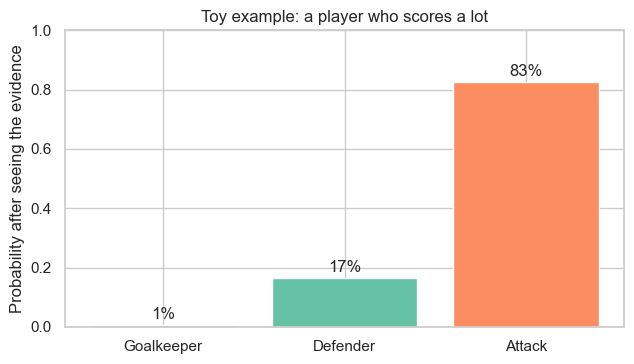

In [18]:
classes = ["Goalkeeper", "Defender", "Attack"]
prior = np.array([0.10, 0.45, 0.45])
likelihood = np.array([0.02, 0.10, 0.50])
score = prior * likelihood
prob = score / score.sum()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(classes, prob, color=["#8da0cb", "#66c2a5", "#fc8d62"])
for i, p in enumerate(prob):
    ax.text(i, p + 0.02, f"{p:.0%}", ha="center")
ax.set_ylim(0, 1)
ax.set_ylabel("Probability after seeing the evidence")
ax.set_title("Toy example: a player who scores a lot")
plt.tight_layout()
fig.savefig(IMG / "nb_ov_01_toy.png", dpi=200, bbox_inches="tight")
plt.show()

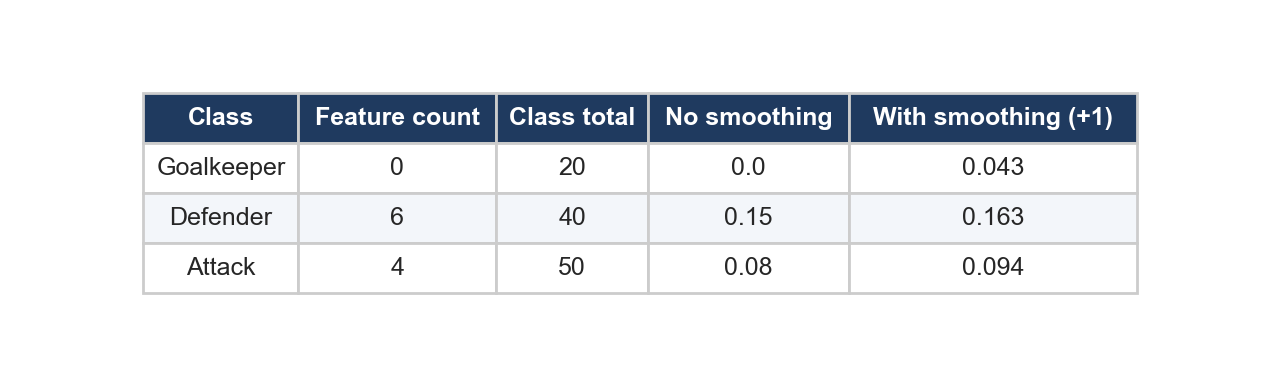

In [19]:
smooth = pd.DataFrame({
    "Class": ["Goalkeeper", "Defender", "Attack"],
    "Feature count": [0, 6, 4],
    "Class total": [20, 40, 50],
})
smooth["No smoothing"] = smooth["Feature count"] / smooth["Class total"]
smooth["With smoothing (+1)"] = (smooth["Feature count"] + 1) / (smooth["Class total"] + 3)
table_image(smooth, IMG / "nb_ov_02_smoothing.png", n=3, decimals=3)

train: 4000  test: 1000  overlap: 0


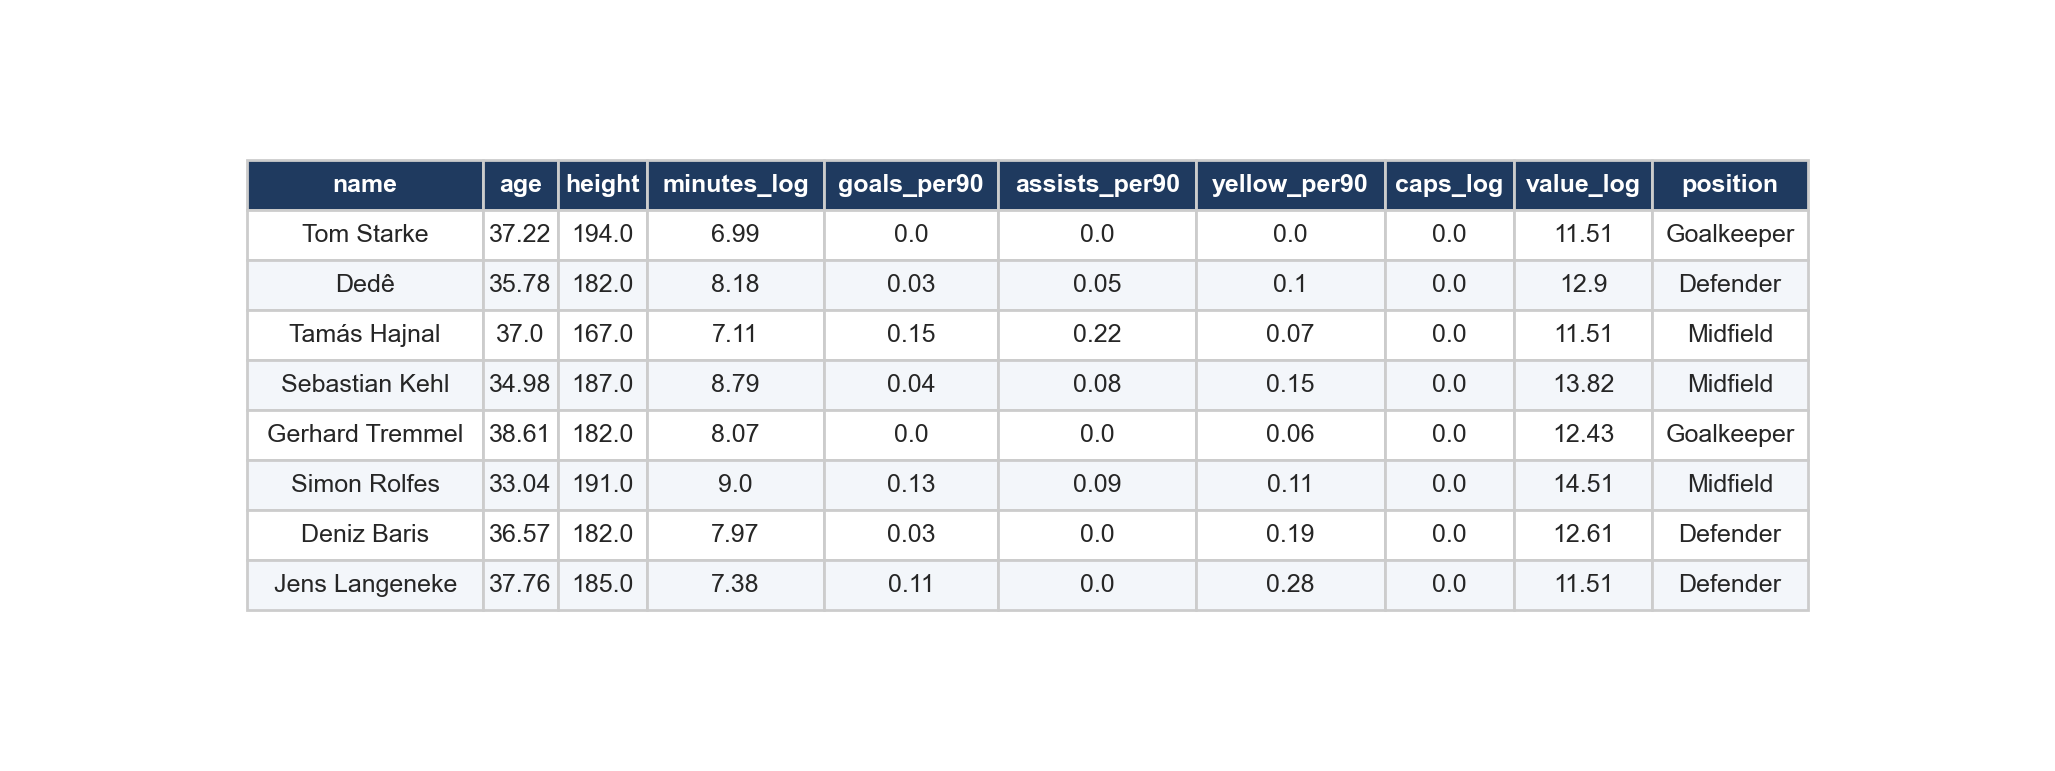

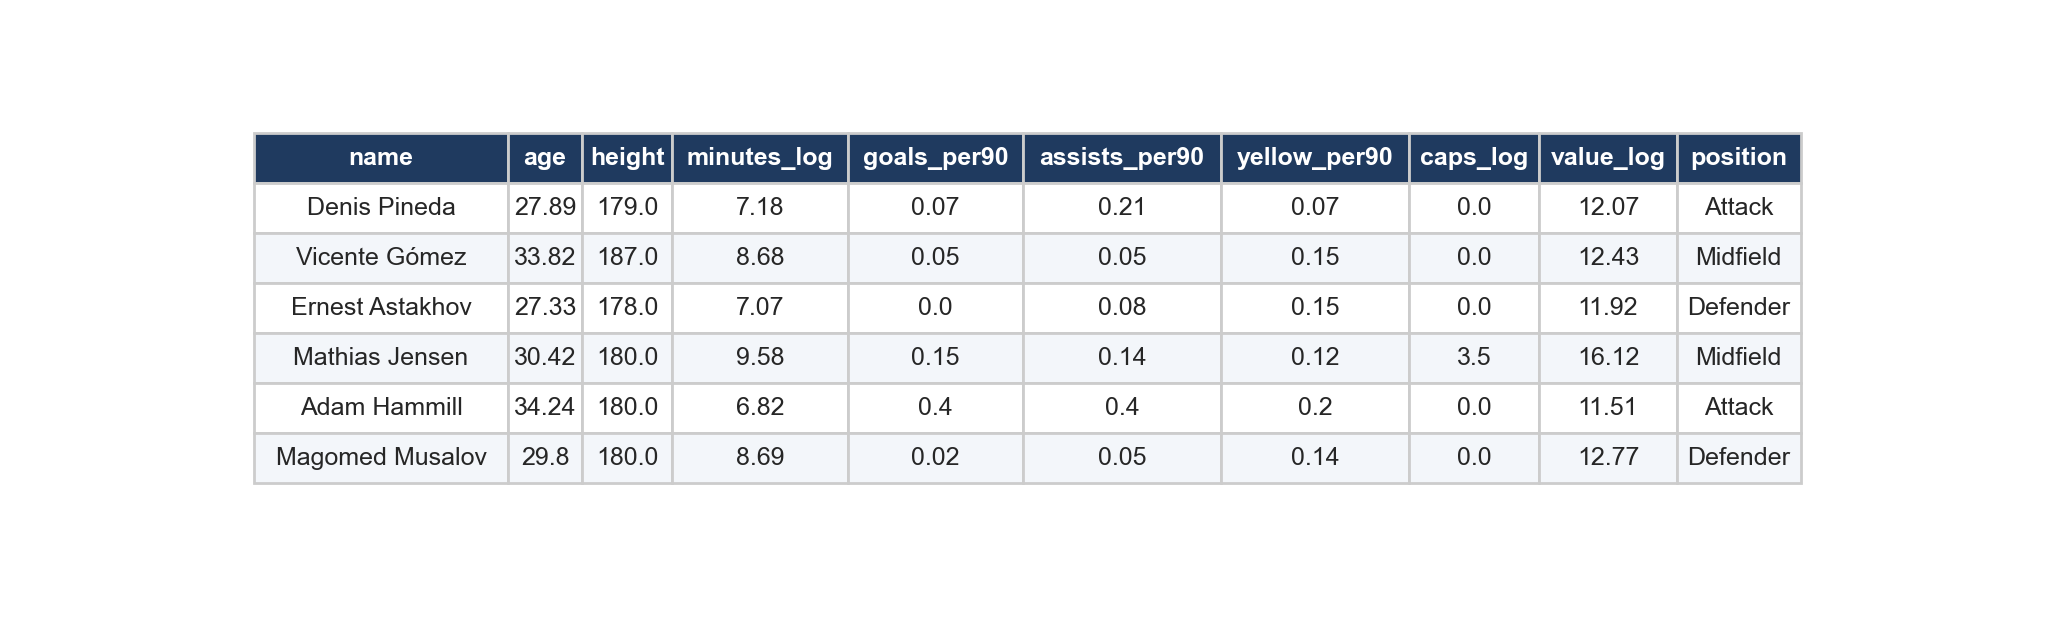

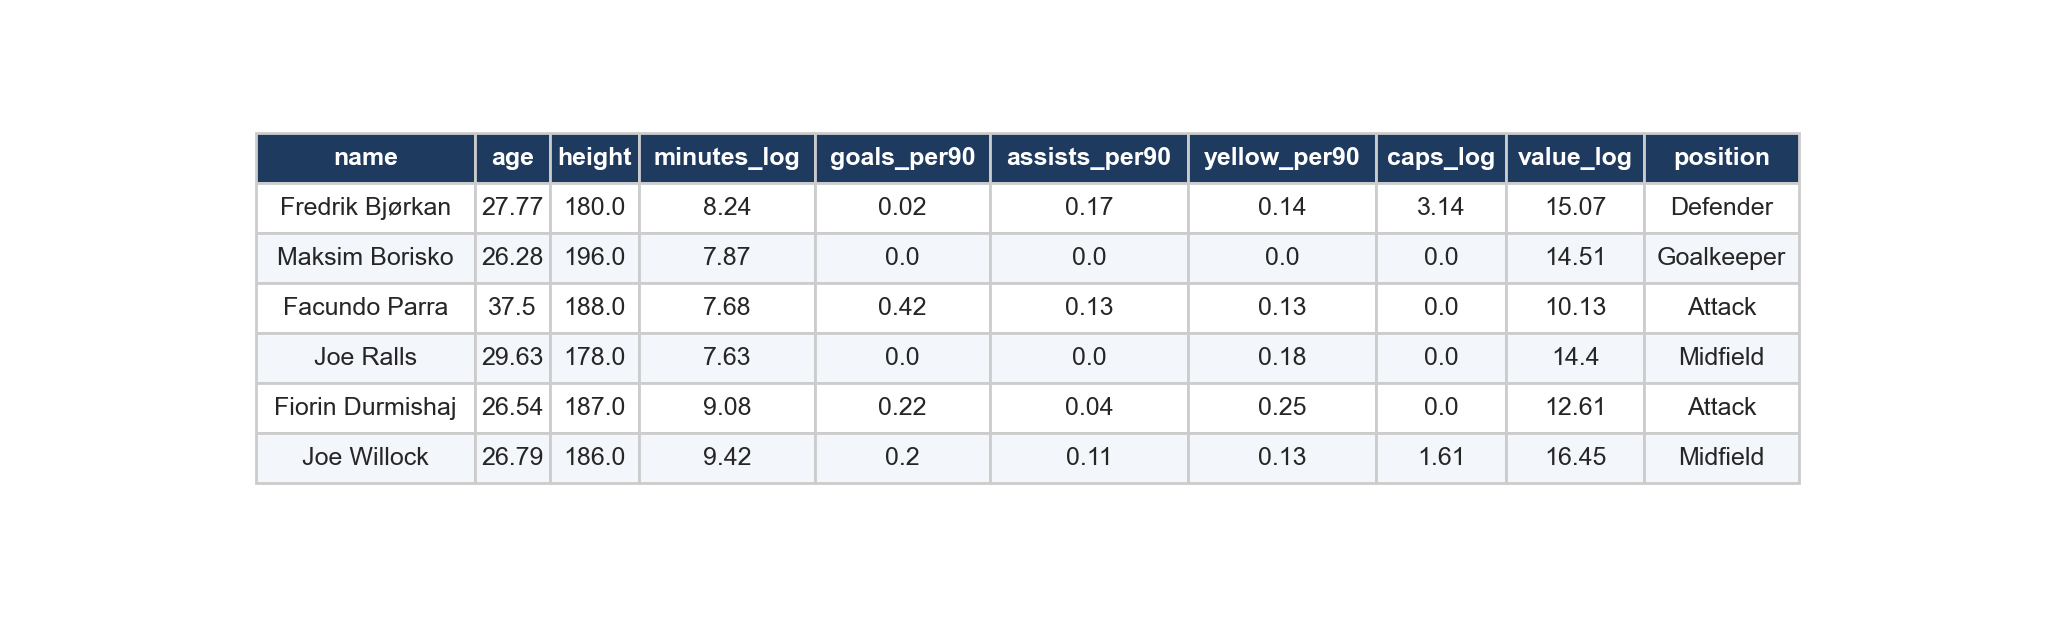

In [5]:
NB_FEATURES = ["age", "height", "minutes_log", "goals_per90", "assists_per90", "yellow_per90", "caps_log", "value_log"]
NB_SHOW = ["name"] + NB_FEATURES + ["position"]

nb_train, nb_test = train_test_split(sample, test_size=TEST_SIZE, stratify=sample.position, random_state=RANDOM_STATE)
assert set(nb_train.index).isdisjoint(nb_test.index), "overlap between train and test!"
print("train:", len(nb_train), " test:", len(nb_test), " overlap:", len(set(nb_train.index) & set(nb_test.index)))

nb_train.to_csv(SAMPLES / "nb_train.csv", index=False)
nb_test.to_csv(SAMPLES / "nb_test.csv", index=False)

table_image(sample[NB_SHOW], IMG / "nb_sample.png")
table_image(nb_train[NB_SHOW], IMG / "nb_train.png", n=6)
table_image(nb_test[NB_SHOW], IMG / "nb_test.png", n=6)

In [6]:
scaler = MinMaxScaler().fit(nb_train[NB_FEATURES])
Xtr = scaler.transform(nb_train[NB_FEATURES])
Xte = np.clip(scaler.transform(nb_test[NB_FEATURES]), 0, 1)
ytr, yte = nb_train.position.values, nb_test.position.values

nb = MultinomialNB(alpha=1.0).fit(Xtr, ytr)
nb_pred = nb.predict(Xte)
nb_acc = accuracy_score(yte, nb_pred)
baseline = pd.Series(yte).value_counts(normalize=True).max()

print(f"accuracy: {nb_acc:.3f}   (always guessing the most common position: {baseline:.3f})")
print()
print(classification_report(yte, nb_pred, labels=POSITIONS))

accuracy: 0.513   (always guessing the most common position: 0.356)

              precision    recall  f1-score   support

  Goalkeeper       0.00      0.00      0.00        83
    Defender       0.47      0.98      0.64       356
    Midfield       0.33      0.13      0.18       295
      Attack       0.84      0.48      0.61       266

    accuracy                           0.51      1000
   macro avg       0.41      0.40      0.36      1000
weighted avg       0.49      0.51      0.44      1000



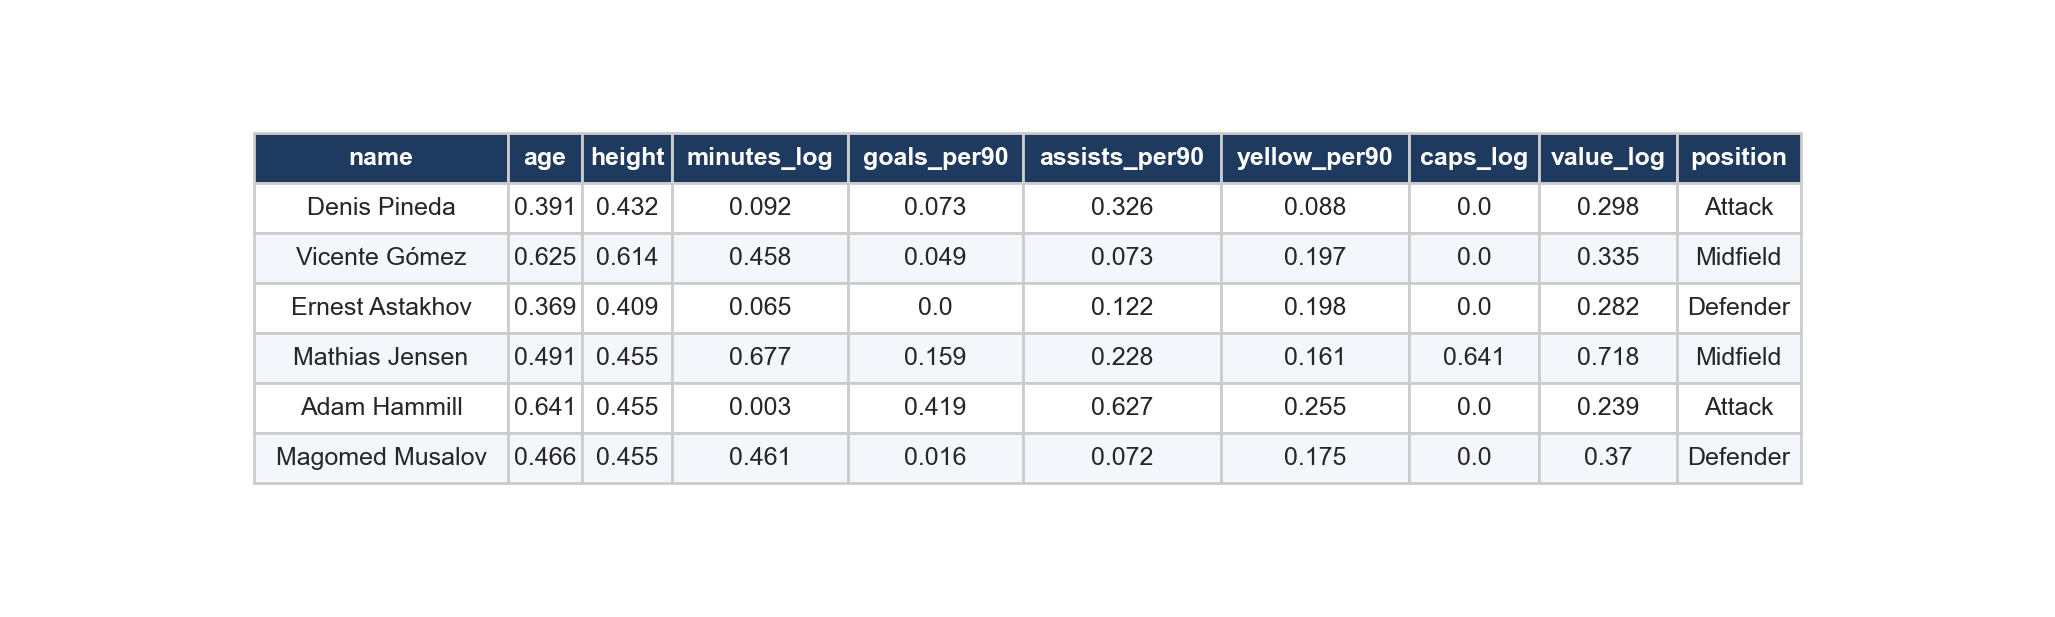

In [20]:
scaled = pd.DataFrame(Xtr, columns=NB_FEATURES)
scaled.insert(0, "name", nb_train.name.values)
scaled["position"] = nb_train.position.values
table_image(scaled, IMG / "nb_scaled.png", n=6, decimals=3)

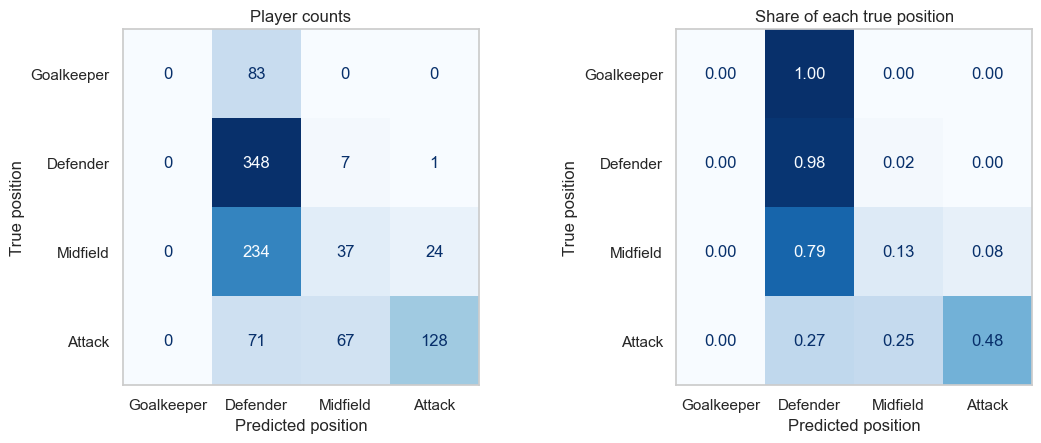

In [7]:
nb_cm = confusion_matrix(yte, nb_pred, labels=POSITIONS)
nb_cm_norm = nb_cm / nb_cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ConfusionMatrixDisplay(nb_cm, display_labels=POSITIONS).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
ConfusionMatrixDisplay(nb_cm_norm, display_labels=POSITIONS).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[0].set_title("Player counts")
axes[1].set_title("Share of each true position")
for ax in axes:
    ax.set_xlabel("Predicted position")
    ax.set_ylabel("True position")
    ax.grid(False)
plt.tight_layout()
fig.savefig(IMG / "nb_01_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

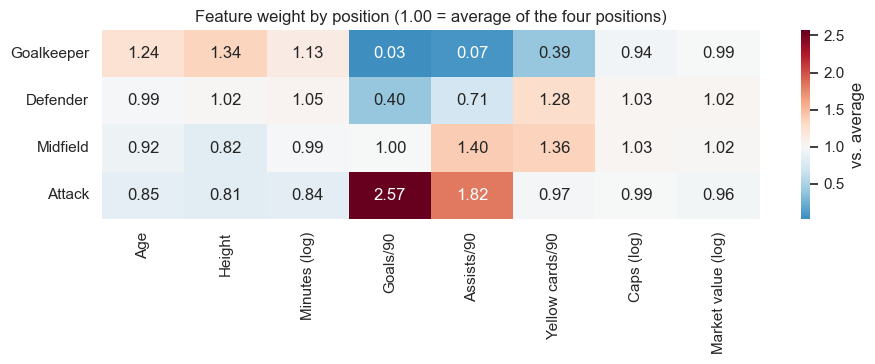

In [8]:
w = pd.DataFrame(np.exp(nb.feature_log_prob_), index=nb.classes_, columns=[NICE[f] for f in NB_FEATURES]).loc[POSITIONS]
rel = w / w.mean(axis=0)

fig, ax = plt.subplots(figsize=(9.5, 3.8))
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0, cbar_kws={"label": "vs. average"}, ax=ax)
ax.tick_params(axis="y", rotation=0)
ax.set_title("Feature weight by position (1.00 = average of the four positions)")
plt.tight_layout()
fig.savefig(IMG / "nb_02_feature_weights.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
med = np.median(Xtr, axis=0)
bern = BernoulliNB().fit((Xtr > med).astype(int), ytr)
gaus = GaussianNB().fit(nb_train[NB_FEATURES], ytr)

variants = {
    "Multinomial NB": nb_acc,
    "Bernoulli NB": accuracy_score(yte, bern.predict((Xte > med).astype(int))),
    "Gaussian NB": accuracy_score(yte, gaus.predict(nb_test[NB_FEATURES])),
}
print(pd.Series(variants).round(3))

Multinomial NB    0.513
Bernoulli NB      0.550
Gaussian NB       0.665
dtype: float64


# Decision Trees:

parent  gini 0.5000  entropy 1.0000
left    gini 0.2188  entropy 0.5436
right   gini 0.3750  entropy 0.8113
weighted gini 0.3125 -> gini gain 0.1875
weighted entropy 0.7042 -> information gain 0.2958


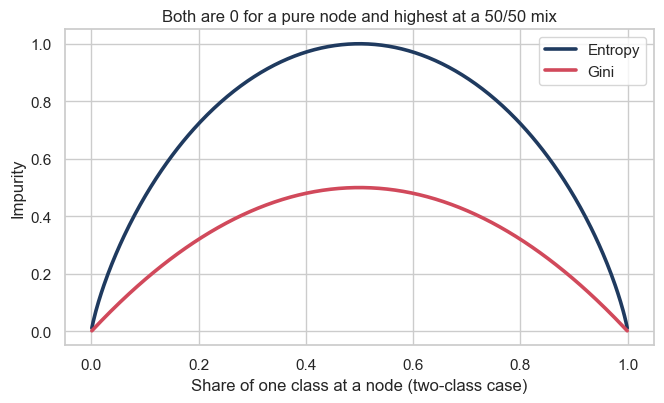

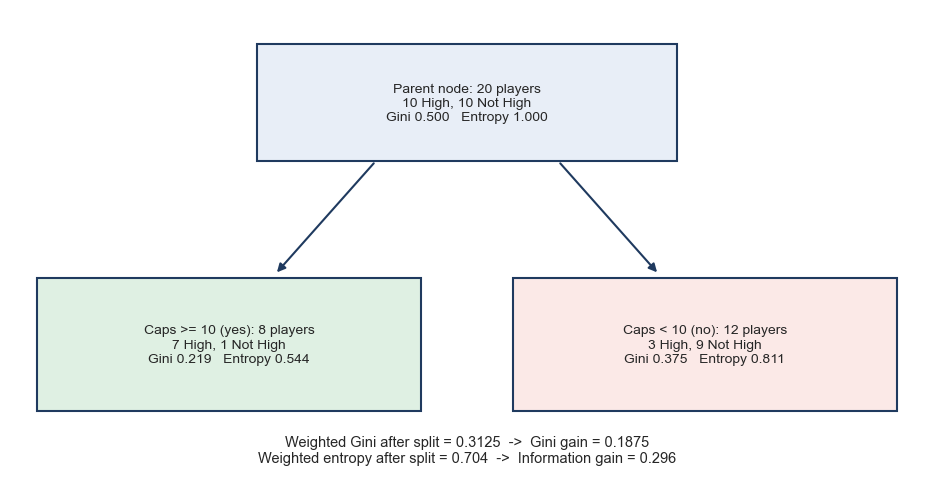

In [10]:
def gini(counts):
    p = np.array(counts) / np.sum(counts)
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = np.array(counts) / np.sum(counts)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

parent, left, right = [10, 10], [7, 1], [3, 9]
n_p, n_l, n_r = 20, 8, 12
w_gini = n_l / n_p * gini(left) + n_r / n_p * gini(right)
w_ent = n_l / n_p * entropy(left) + n_r / n_p * entropy(right)
gini_gain = gini(parent) - w_gini
info_gain = entropy(parent) - w_ent

print(f"parent  gini {gini(parent):.4f}  entropy {entropy(parent):.4f}")
print(f"left    gini {gini(left):.4f}  entropy {entropy(left):.4f}")
print(f"right   gini {gini(right):.4f}  entropy {entropy(right):.4f}")
print(f"weighted gini {w_gini:.4f} -> gini gain {gini_gain:.4f}")
print(f"weighted entropy {w_ent:.4f} -> information gain {info_gain:.4f}")

p = np.linspace(0.001, 0.999, 400)
g = 2 * p * (1 - p)
e = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.plot(p, e, lw=2.6, color="#1f3a5f", label="Entropy")
ax.plot(p, g, lw=2.6, color="#d1495b", label="Gini")
ax.set_xlabel("Share of one class at a node (two-class case)")
ax.set_ylabel("Impurity")
ax.set_title("Both are 0 for a pure node and highest at a 50/50 mix")
ax.legend()
plt.tight_layout()
fig.savefig(IMG / "dt_ov_01_impurity.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 6.2)
def box(x, y, w, h, text, color):
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, fc=color, ec="#1f3a5f", lw=1.5, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=10, zorder=3)
box(5, 5.0, 4.6, 1.5, f"Parent node: 20 players\n10 High, 10 Not High\nGini {gini(parent):.3f}   Entropy {entropy(parent):.3f}", "#e8eef7")
box(2.4, 1.9, 4.2, 1.7, f"Caps >= 10 (yes): 8 players\n7 High, 1 Not High\nGini {gini(left):.3f}   Entropy {entropy(left):.3f}", "#dff0e3")
box(7.6, 1.9, 4.2, 1.7, f"Caps < 10 (no): 12 players\n3 High, 9 Not High\nGini {gini(right):.3f}   Entropy {entropy(right):.3f}", "#fbe9e7")
ax.annotate("", xy=(2.9, 2.8), xytext=(4.0, 4.25), arrowprops=dict(arrowstyle="-|>", color="#1f3a5f", lw=1.5))
ax.annotate("", xy=(7.1, 2.8), xytext=(6.0, 4.25), arrowprops=dict(arrowstyle="-|>", color="#1f3a5f", lw=1.5))
ax.text(5, 0.55, f"Weighted Gini after split = {w_gini:.4f}  ->  Gini gain = {gini_gain:.4f}\n"
                 f"Weighted entropy after split = {w_ent:.3f}  ->  Information gain = {info_gain:.3f}",
        ha="center", va="center", fontsize=10.5)
plt.tight_layout()
fig.savefig(IMG / "dt_ov_02_worked_split.png", dpi=200, bbox_inches="tight")
plt.show()

train: 4000  test: 1000  overlap: 0


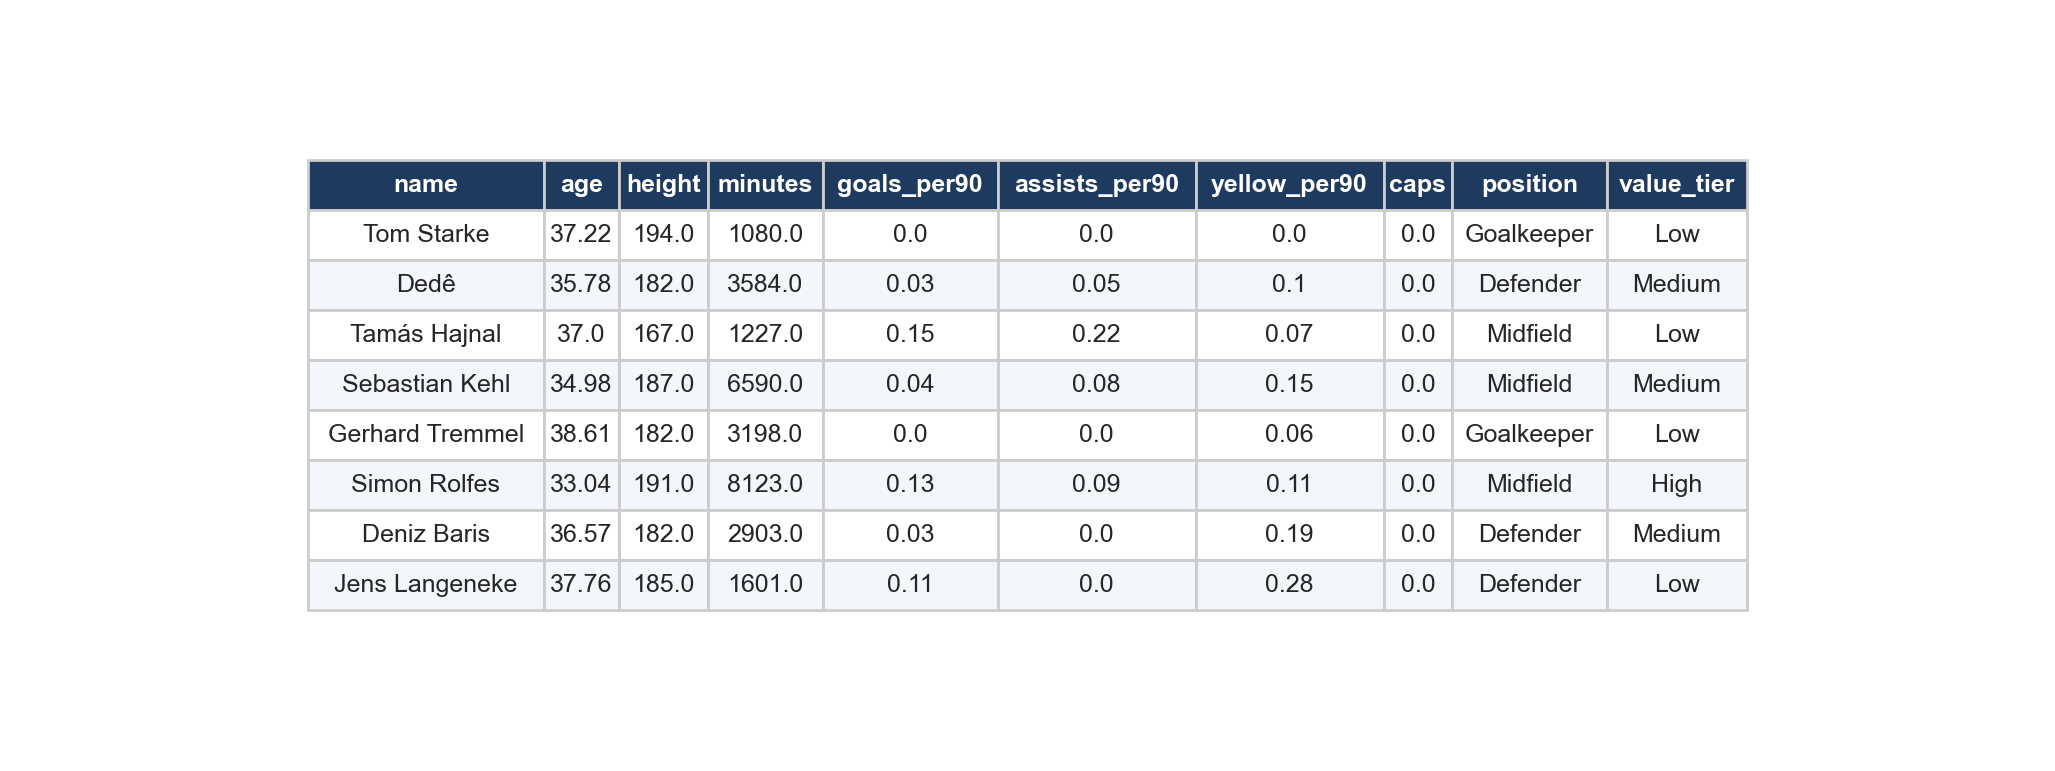

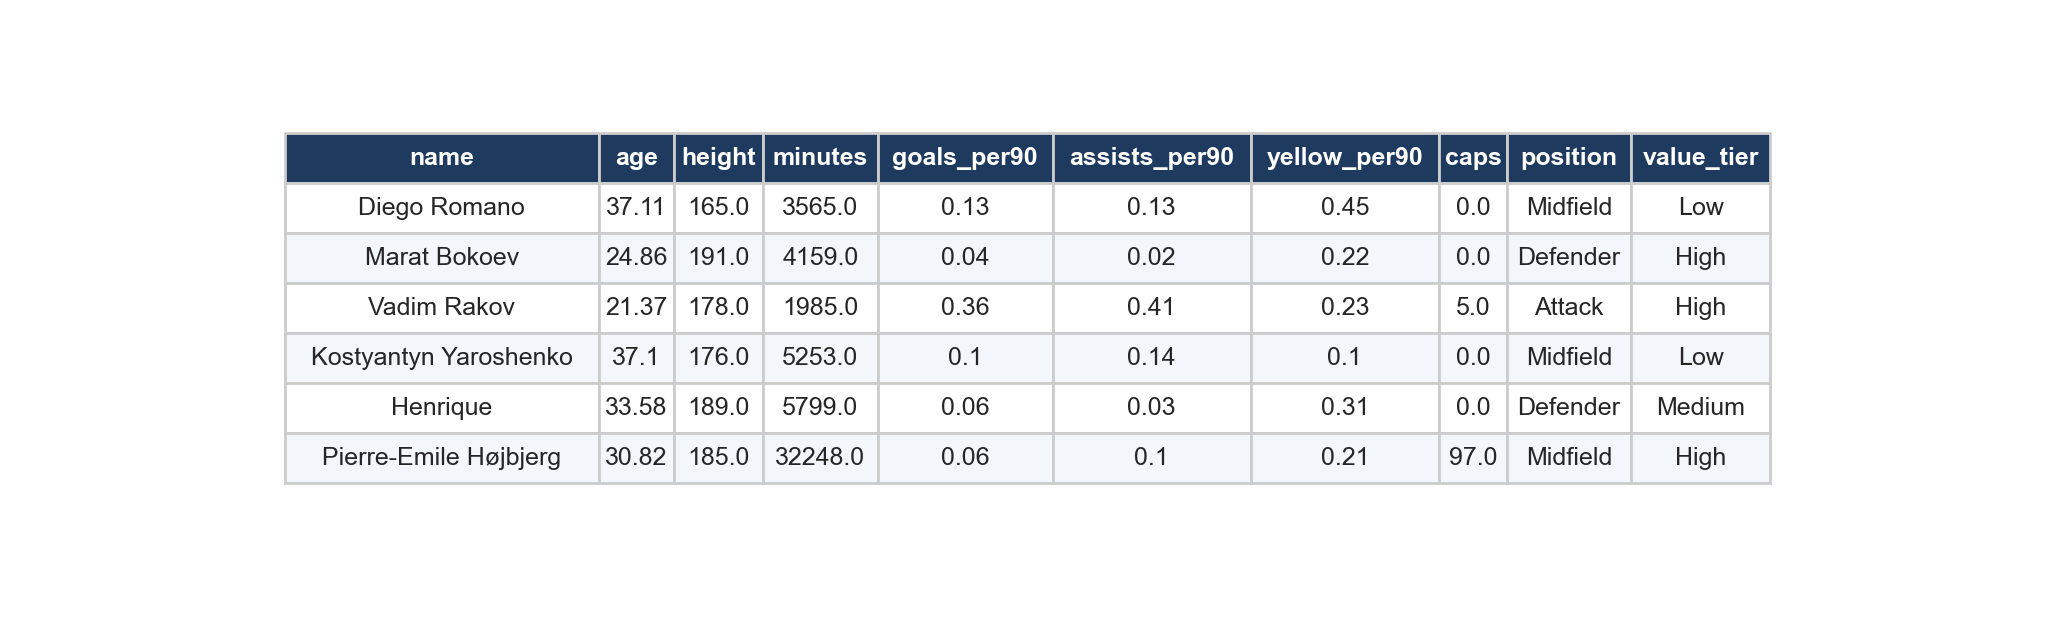

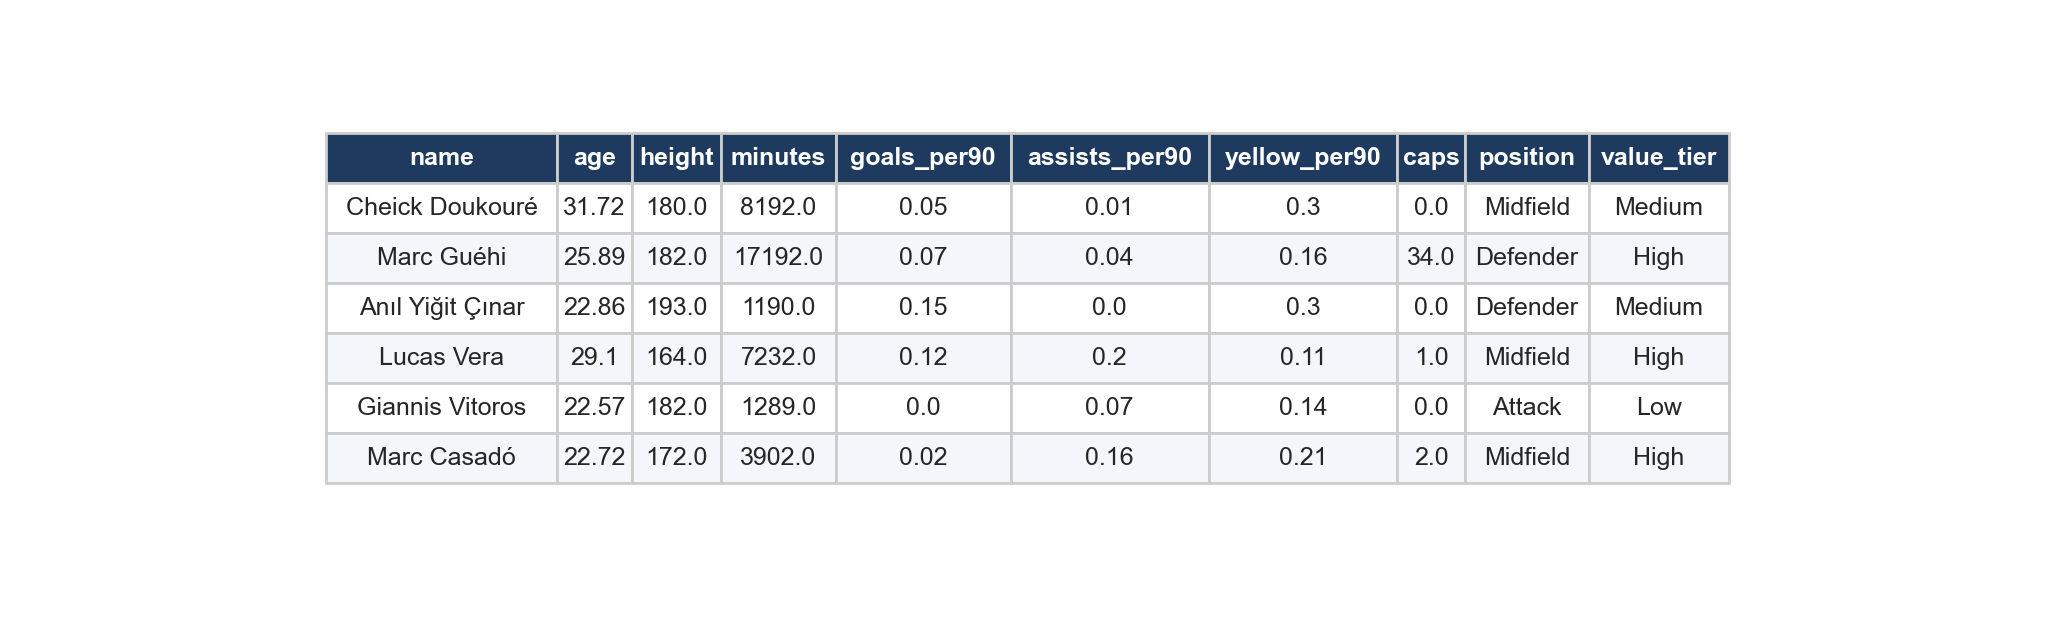

In [11]:
DT_BASE = ["age", "height", "minutes", "goals_per90", "assists_per90", "yellow_per90", "caps"]
POS_COLS = [f"pos_{p}" for p in POSITIONS]
DT_FEATURES = DT_BASE + POS_COLS
DT_SHOW = ["name"] + DT_BASE + ["position", "value_tier"]

dt_data = pd.concat([sample, pd.get_dummies(sample.position, prefix="pos", dtype=int)[POS_COLS]], axis=1)

dt_train, dt_test = train_test_split(dt_data, test_size=TEST_SIZE, stratify=dt_data.value_tier, random_state=RANDOM_STATE)
assert set(dt_train.index).isdisjoint(dt_test.index), "overlap between train and test!"
print("train:", len(dt_train), " test:", len(dt_test), " overlap:", len(set(dt_train.index) & set(dt_test.index)))

dt_train.to_csv(SAMPLES / "dt_train.csv", index=False)
dt_test.to_csv(SAMPLES / "dt_test.csv", index=False)

table_image(dt_data[DT_SHOW], IMG / "dt_sample.png")
table_image(dt_train[DT_SHOW], IMG / "dt_train.png", n=6)
table_image(dt_test[DT_SHOW], IMG / "dt_test.png", n=6)

Xtr_dt, ytr_dt = dt_train[DT_FEATURES], dt_train.value_tier
Xte_dt, yte_dt = dt_test[DT_FEATURES], dt_test.value_tier

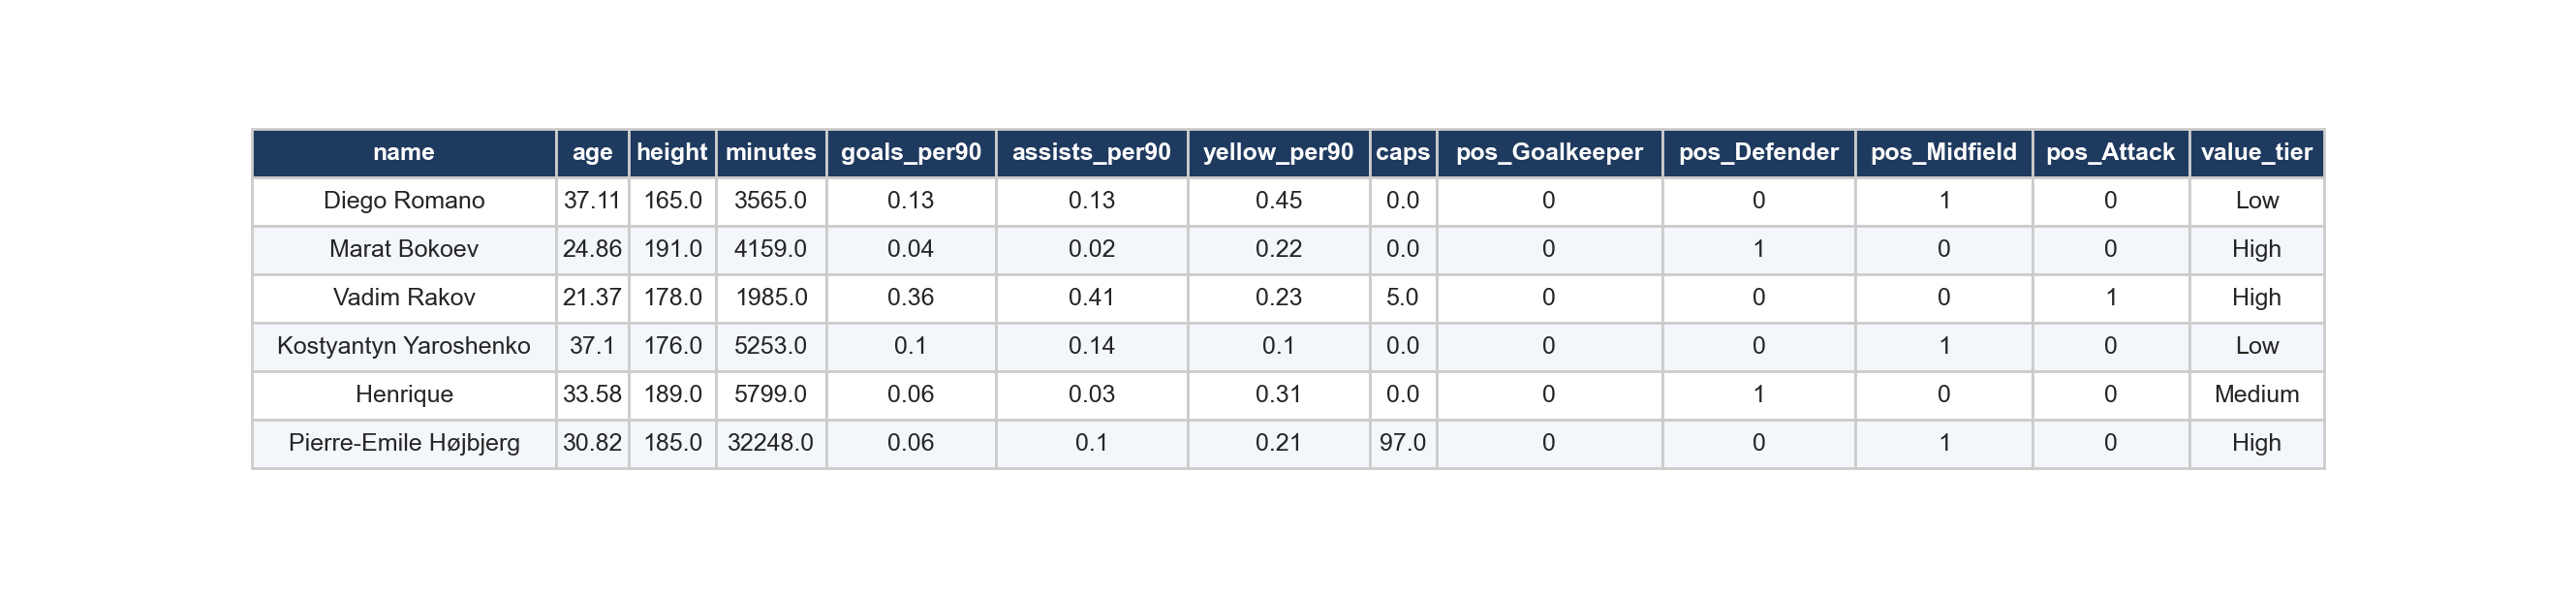

In [21]:
table_image(dt_train[["name"] + DT_FEATURES + ["value_tier"]], IMG / "dt_model_ready.png", n=6)

In [12]:
tree_specs = {
    "Tree 1": ("Gini", dict(criterion="gini", max_depth=3)),
    "Tree 2": ("Entropy", dict(criterion="entropy", max_depth=4)),
    "Tree 3": ("Gini", dict(criterion="gini", max_depth=6, min_samples_leaf=25)),
}
fitted, rows = {}, []
for name, (label, params) in tree_specs.items():
    model = DecisionTreeClassifier(random_state=RANDOM_STATE, **params).fit(Xtr_dt, ytr_dt)
    pred = model.predict(Xte_dt)
    fitted[name] = (model, pred)
    rows.append({"tree": name, "criterion": label, "max_depth": params["max_depth"],
                 "min_leaf": params.get("min_samples_leaf", 1), "leaves": model.get_n_leaves(),
                 "train_acc": accuracy_score(ytr_dt, model.predict(Xtr_dt)),
                 "test_acc": accuracy_score(yte_dt, pred)})
tree_table = pd.DataFrame(rows)
print(tree_table.round(3).to_string(index=False))

  tree criterion  max_depth  min_leaf  leaves  train_acc  test_acc
Tree 1      Gini          3         1       8      0.628     0.590
Tree 2   Entropy          4         1      16      0.646     0.605
Tree 3      Gini          6        25      49      0.680     0.603


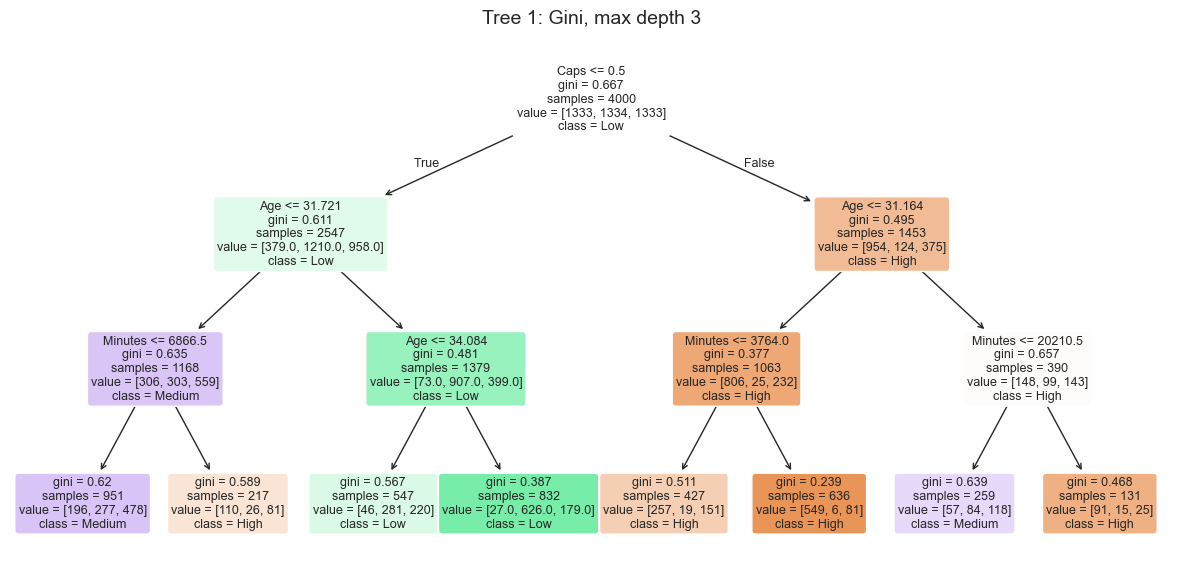

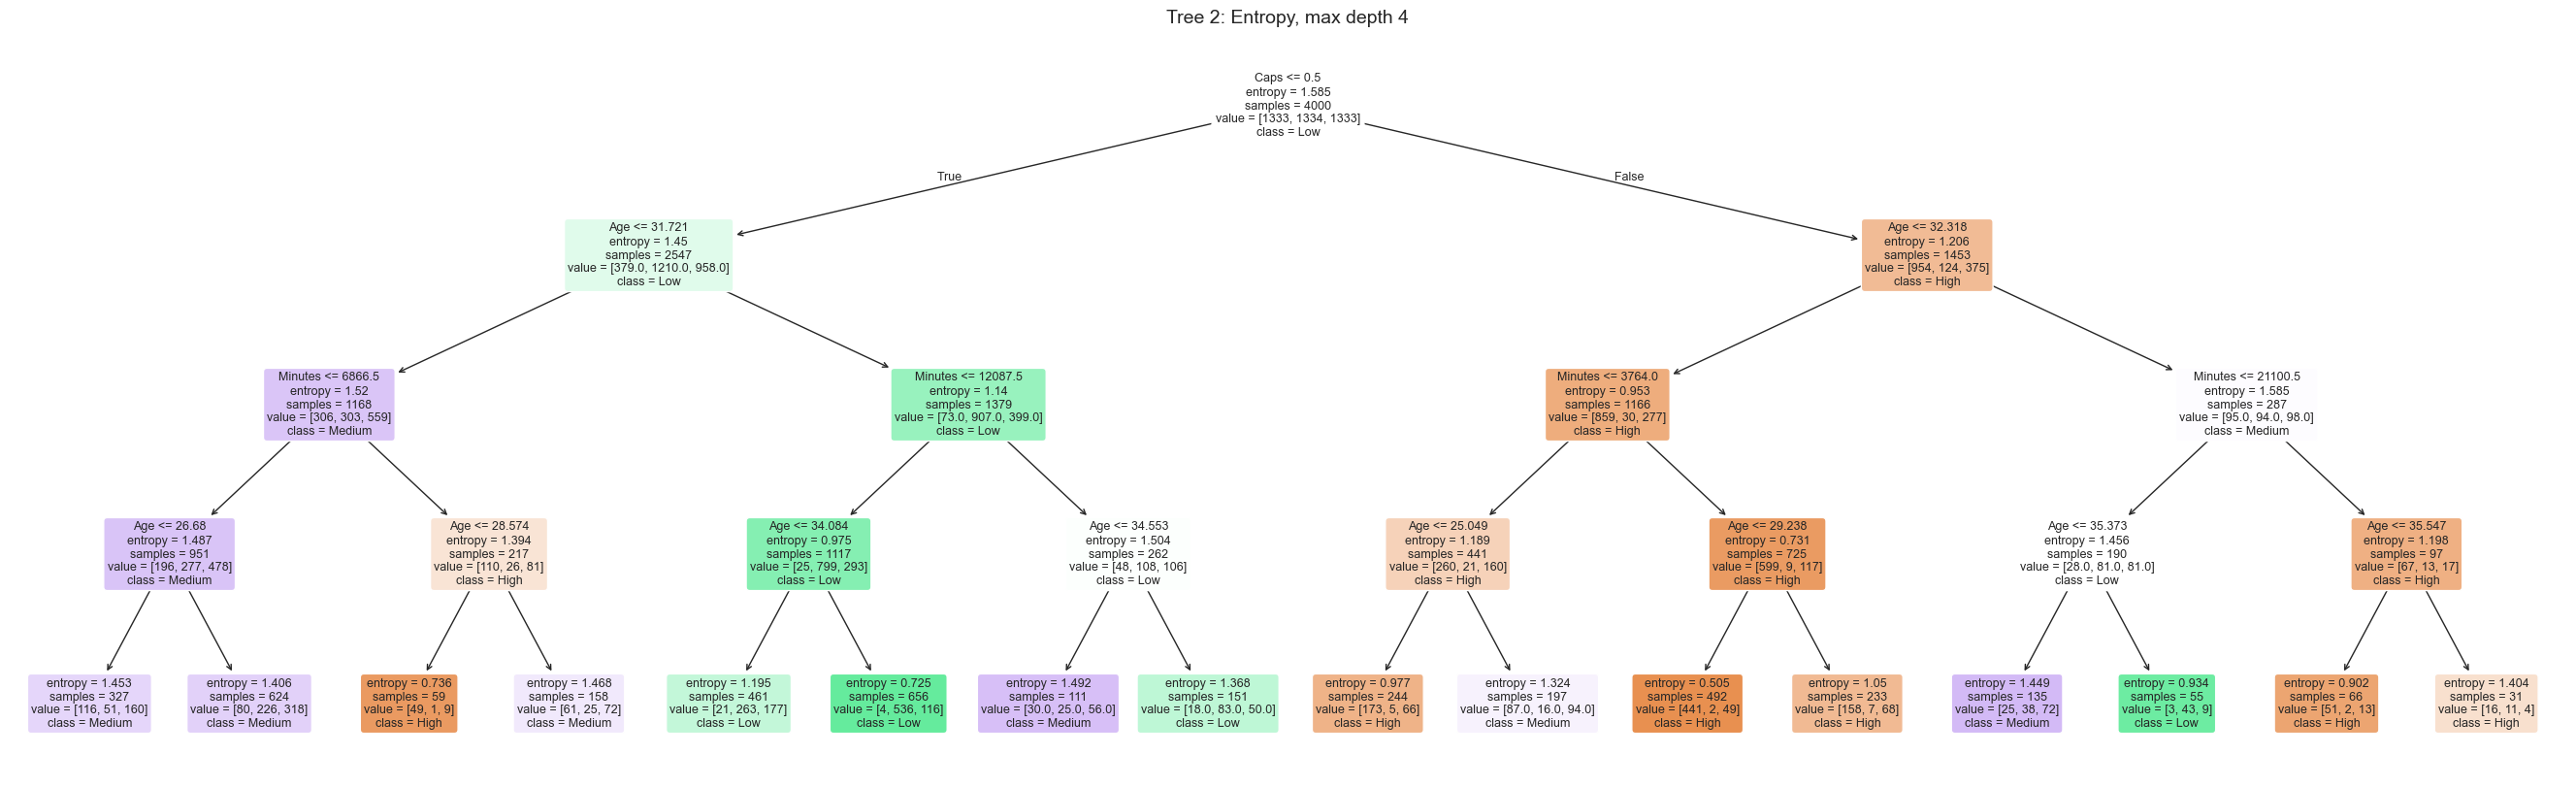

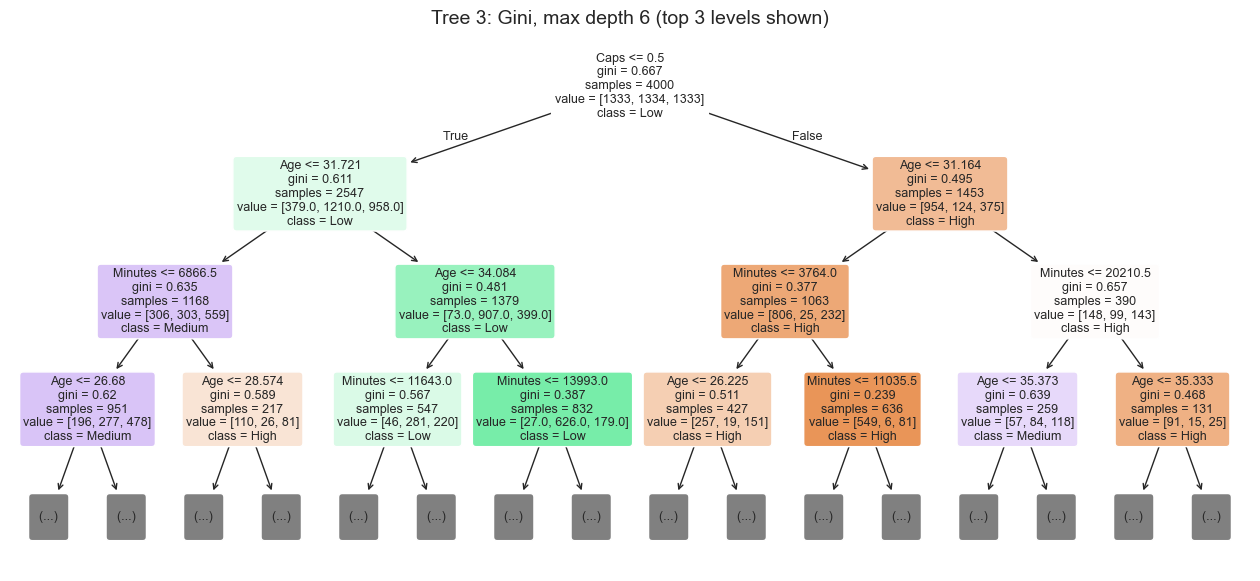

In [13]:
def draw_tree(model, title, path, size, shown_depth=None):
    fig, ax = plt.subplots(figsize=size)
    plot_tree(model, feature_names=[NICE[f] for f in DT_FEATURES], class_names=list(model.classes_),
              filled=True, rounded=True, fontsize=9, max_depth=shown_depth, ax=ax)
    ax.set_title(title, fontsize=14)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

draw_tree(fitted["Tree 1"][0], "Tree 1: Gini, max depth 3", IMG / "dt_01_tree1.png", (15, 7))
draw_tree(fitted["Tree 2"][0], "Tree 2: Entropy, max depth 4", IMG / "dt_02_tree2.png", (34, 10))
draw_tree(fitted["Tree 3"][0], "Tree 3: Gini, max depth 6 (top 3 levels shown)", IMG / "dt_03_tree3.png", (16, 7), shown_depth=3)

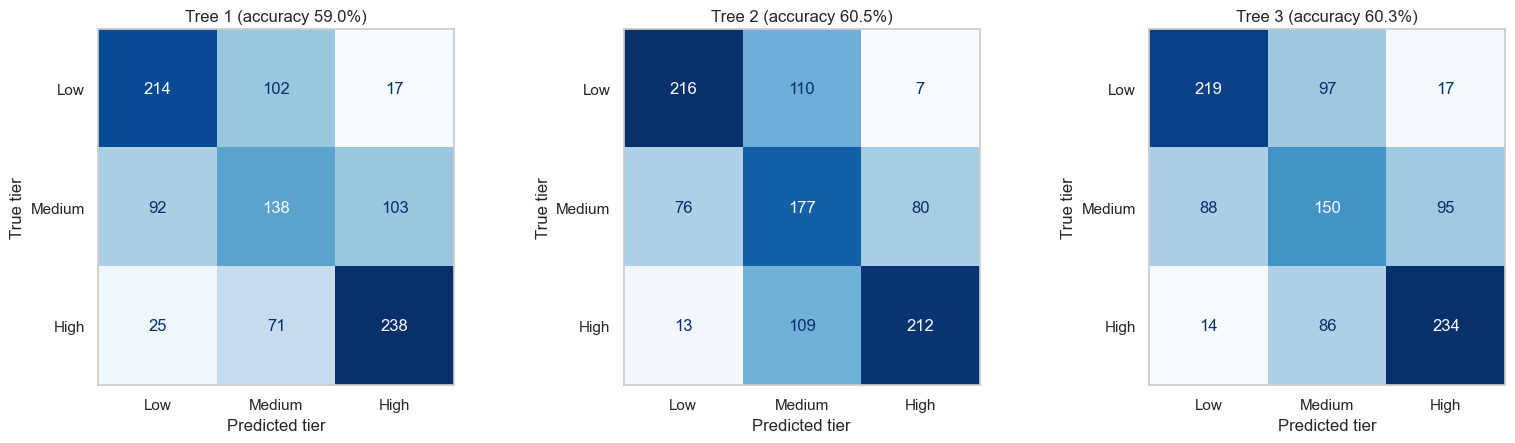

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, (model, pred)) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_predictions(yte_dt, pred, labels=TIERS, ax=ax, cmap="Blues", colorbar=False)
    acc = accuracy_score(yte_dt, pred)
    ax.set_title(f"{name} (accuracy {acc:.1%})")
    ax.set_xlabel("Predicted tier")
    ax.set_ylabel("True tier")
    ax.grid(False)
plt.tight_layout()
fig.savefig(IMG / "dt_04_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

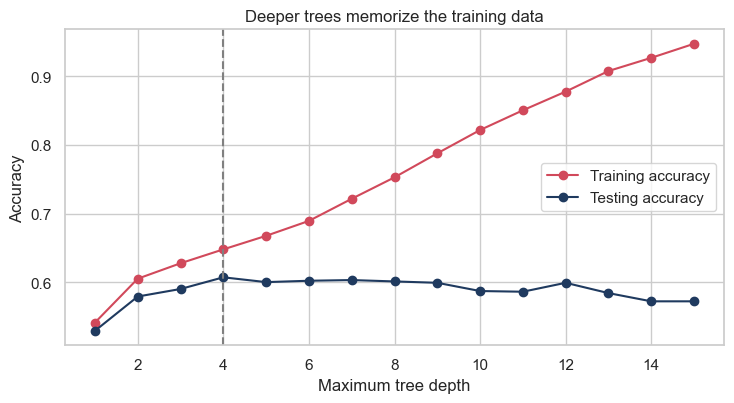

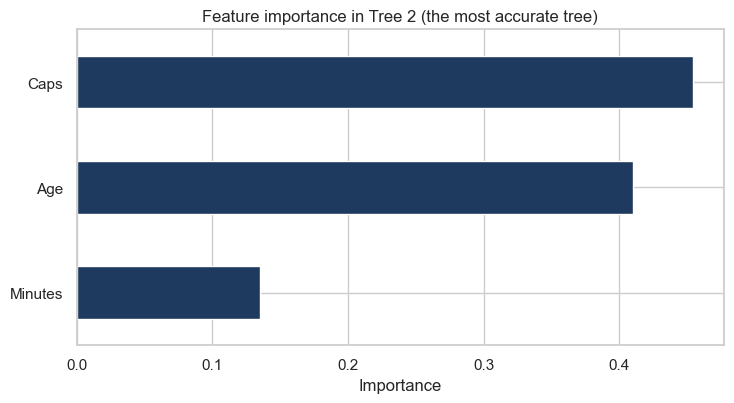

best tree: Tree 2 | best depth on the curve: 4


In [15]:
depths = list(range(1, 16))
tr_acc, te_acc = [], []
for k in depths:
    m = DecisionTreeClassifier(max_depth=k, random_state=RANDOM_STATE).fit(Xtr_dt, ytr_dt)
    tr_acc.append(accuracy_score(ytr_dt, m.predict(Xtr_dt)))
    te_acc.append(accuracy_score(yte_dt, m.predict(Xte_dt)))
best_depth = depths[int(np.argmax(te_acc))]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(depths, tr_acc, marker="o", color="#d1495b", label="Training accuracy")
ax.plot(depths, te_acc, marker="o", color="#1f3a5f", label="Testing accuracy")
ax.axvline(best_depth, ls="--", color="gray")
ax.set_xlabel("Maximum tree depth"); ax.set_ylabel("Accuracy")
ax.set_title("Deeper trees memorize the training data")
ax.legend()
plt.tight_layout()
fig.savefig(IMG / "dt_05_depth_curve.png", dpi=200, bbox_inches="tight")
plt.show()

best_tree = tree_table.sort_values("test_acc", ascending=False).iloc[0].tree
best_model = fitted[best_tree][0]
imp = pd.Series(best_model.feature_importances_, index=[NICE[f] for f in DT_FEATURES]).sort_values()
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
imp.plot.barh(ax=ax, color="#1f3a5f")
ax.set_title(f"Feature importance in {best_tree} (the most accurate tree)")
ax.set_xlabel("Importance")
plt.tight_layout()
fig.savefig(IMG / "dt_06_importances.png", dpi=200, bbox_inches="tight")
plt.show()
print("best tree:", best_tree, "| best depth on the curve:", best_depth)